In [80]:
# Sugar Trap: Market Gap Analysis
# Amalitech Data Engineering Project Assessment

"""
Objective:
Identify potential nutritional gaps in the snack market by
analyzing product categories, sugar, protein, and ingredients.
"""

# 1. Environment setup
!pip install -q pandas requests matplotlib seaborn numpy

In [81]:
import requests
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np

In [40]:
DATA_URL = (
    "https://static.openfoodfacts.org/data/"
    "en.openfoodfacts.org.products.csv"
)

REQUIRED_COLUMNS = [
    "code",
    "product_name",
    "categories_tags",
    "sugars_100g",
    "proteins_100g",
    "fat_100g",
    "fiber_100g",
    "ingredients_text"
]

SAMPLE_SIZE = 500_000
CHUNK_SIZE = 25_000

In [41]:
response = requests.get(
    DATA_URL,
    stream=True,
    headers={"User-Agent": "SugarTrapAnalysis/1.0"},
    timeout=(30, 300)
)

response.raise_for_status()
response.raw.decode_content = True

chunks = []
rows_collected = 0

try:
    reader = pd.read_csv(
        response.raw,
        sep="\t",
        usecols=REQUIRED_COLUMNS,
        chunksize=CHUNK_SIZE,
        low_memory=False
    )

    for chunk in reader:

        remaining = SAMPLE_SIZE - rows_collected

        if len(chunk) > remaining:
            chunk = chunk.iloc[:remaining]

        chunks.append(chunk)
        rows_collected += len(chunk)

        print(f"Collected: {rows_collected:,}")

        if rows_collected >= SAMPLE_SIZE:
            break

finally:
    response.close()

raw_df = pd.concat(chunks, ignore_index=True)
del chunks

print("\nFinal dataset shape:", raw_df.shape)

Collected: 25,000
Collected: 50,000
Collected: 75,000
Collected: 100,000
Collected: 125,000
Collected: 150,000
Collected: 175,000
Collected: 200,000
Collected: 225,000
Collected: 250,000
Collected: 275,000
Collected: 300,000
Collected: 325,000
Collected: 350,000
Collected: 375,000
Collected: 400,000
Collected: 425,000
Collected: 450,000
Collected: 475,000
Collected: 500,000

Final dataset shape: (500000, 8)


In [42]:
# Extract individual category tags

category_tags = (
    raw_df["categories_tags"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

# Identify tags related to our six target categories

keywords = (
    r"biscuit|nut|bar|chip|crisp|cracker|"
    r"confection|candy|sweet"
)

relevant_tags = category_tags[
    category_tags.str.contains(
        keywords,
        case=False,
        na=False
    )
]

# Count occurrences of each category tag

tag_counts = relevant_tags.value_counts()

display(tag_counts.head(80).to_frame("Product Count"))

,Product Count
categories_tags,
en:sweet-snacks,31053
en:confectioneries,14993
en:biscuits-and-cakes,13718
en:biscuits,6844
en:chips-and-fries,3320
...,...
en:wheat-crackers,39
en:nut-oils,37
en:sweet-potatoes,36


In [43]:
category_patterns = {
    "Biscuits": r"biscuit|cookie",
    "Nuts": r"nut|peanut|almond|cashew|pistachio|walnut",
    "Snack Bars": r"bar",
    "Chips": r"chip|crisp",
    "Crackers": r"cracker",
    "Confectionery": r"confection|candy|chocolate|sweet"
}

for category, pattern in category_patterns.items():

    print(f"\n{'=' * 20} {category} {'=' * 20}")

    matches = tag_counts[
        tag_counts.index.str.contains(
            pattern,
            case=False,
            regex=True,
            na=False
        )
    ]

    display(matches.head(25).to_frame("Product Count"))


==================== Biscuits ====================


,Product Count
categories_tags,
en:biscuits-and-cakes,13718
en:biscuits,6844
en:biscuits-and-crackers,3310
en:chocolate-biscuits,415
en:filled-biscuits,147
en:chocolate-chip-cookies,142
en:dry-biscuits,107
en:sandwich-biscuits,48
en:chocolate-biscuity-bars,33



==================== Nuts ====================


,Product Count
categories_tags,
en:nuts-and-their-products,2977
en:nuts,1740
en:peanut-butters,961
en:nut-butters,639
en:peanuts,484
en:roasted-nuts,259
en:nut-based-drinks,233
en:roasted-peanuts,229
en:coconut-milks-and-creams,215



==================== Snack Bars ====================


,Product Count
categories_tags,
en:bars,1398
en:cereal-bars,657
en:barbecue-sauces,523
en:candy-chocolate-bars,160
en:protein-bars,154
en:ice-cream-bars,130
en:barn-chicken-eggs,106
en:nut-bars,69
en:dark-chocolate-bar,65


... (2 outputs left out)


==================== Crackers ====================


,Product Count
categories_tags,
en:biscuits-and-crackers,3310
en:crackers-appetizers,1521
en:crackers,77
en:wheat-crackers,39
en:small-crackers,23
en:Crackers,17
en:rice-crackers,16
en:crackers-breakfast,12
en:cracker,10



==================== Confectionery ====================


,Product Count
categories_tags,
en:sweet-snacks,31053
en:confectioneries,14993
en:sweeteners,3179
en:sweet-spreads,3069
en:sweetened-beverages,769
en:artificially-sweetened-beverages,540
en:unsweetened-beverages,491
en:chocolate-biscuits,415
en:sweet-pastries-and-pies,331


## 6. Snack Category Extraction

Products are classified into six high-level categories
using explicit Open Food Facts category tags.

When a product matches multiple categories, a predefined
priority determines its primary category.

In [44]:
CATEGORY_TAGS = {
    "Snack Bars": {
        "en:cereal-bars",
        "en:protein-bars",
        "en:energy-bars",
        "en:fruits-cereal-bars",
        "en:nut-bars",
        "en:protein-energy-bars",
        "en:snack-bar",
        "en:cereal-bars-with-nuts",
        "en:chocolate-cereal-bars",
        "en:peanut-bars"
    },

    "Biscuits": {
        "en:biscuits"
    },

    "Crackers": {
        "en:crackers",
        "en:crackers-appetizers",
        "en:wheat-crackers",
        "en:small-crackers",
        "en:rice-crackers",
        "en:crackers-breakfast",
        "en:graham-crackers",
        "en:sandwich-crackers",
        "en:baked-snack-crackers",
        "en:baked-crackers",
        "en:cheese-crackers",
        "en:cream-crackers",
        "en:bite-size-crackers"
    },

    "Chips": {
        "en:crisps",
        "en:potato-crisps",
        "en:corn-chips",
        "en:flavoured-potato-crisps",
        "en:stacked-extruded-potato-crisps",
        "en:plantain-chips",
        "en:pita-chips",
        "en:potato-crisps-in-sunflower-oil",
        "en:flavoured-corn-crisps",
        "en:chips",
        "en:ketchup-crisps",
        "en:salt-and-vinegar-crisps",
        "en:barbecue-crisps",
        "en:plantain-crisps",
        "en:wavy-potato-crisps",
        "en:crisps-made-from-reconstituted-potato"
    },

    "Confectionery": {
        "en:confectioneries",
        "en:candy-chocolate-bars",
        "en:chocolate-covered-nuts",
        "en:chocolate-covered-nuts-and-fruits",
        "en:nut-confectioneries",
        "en:fruit-confectioneries",
        "en:candy-canes",
        "en:chocolates-with-hazelnuts",
        "en:dark-chocolate-bar",
        "en:milk-chocolate-bar"
    },

    "Nuts": {
        "en:nuts",
        "en:peanuts",
        "en:roasted-nuts",
        "en:roasted-peanuts",
        "en:salted-nuts",
        "en:cashew-nuts",
        "en:shelled-nuts",
        "en:walnuts"
    }
}

CATEGORY_PRIORITY = list(CATEGORY_TAGS.keys())

print("Configured categories:")
print(CATEGORY_PRIORITY)

Configured categories:
['Snack Bars', 'Biscuits', 'Crackers', 'Chips', 'Confectionery', 'Nuts']


In [45]:
def get_matching_categories(category_string):

    if not isinstance(category_string, str):
        return []

    product_tags = {
        tag.strip().lower()
        for tag in category_string.split(",")
        if tag.strip()
    }

    matched = []

    for category in CATEGORY_PRIORITY:

        if product_tags.intersection(CATEGORY_TAGS[category]):
            matched.append(category)

    return matched

In [46]:
# Identify all matching categories for each product

matched_categories = raw_df["categories_tags"].apply(
    get_matching_categories
)

# Assign the highest-priority matching category

raw_df["primary_category"] = matched_categories.apply(
    lambda categories: categories[0] if categories else pd.NA
)

# Extract all products belonging to our six categories

snack_df = raw_df[
    raw_df["primary_category"].notna()
].copy()

print("Original records:", len(raw_df))
print("Matching snack products:", len(snack_df))

print(
    "Products matching multiple categories:",
    matched_categories.apply(lambda categories: len(categories) > 1).sum()
)

Original records: 500000
Matching snack products: 29152
Products matching multiple categories: 391


In [47]:
category_counts = (
    snack_df["primary_category"]
    .value_counts()
    .reindex(CATEGORY_PRIORITY, fill_value=0)
)

display(category_counts.to_frame("Product Count"))

print("\nTotal snack products:", category_counts.sum())

,Product Count
primary_category,
Snack Bars,897
Biscuits,6821
Crackers,1370
Chips,3296
Confectionery,15040
Nuts,1728



Total snack products: 29152


In [48]:
# Check data quality in the extracted snack dataset

duplicate_codes = snack_df.loc[
    snack_df["code"].notna() &
    snack_df["code"].duplicated(keep=False),
    "code"
]

multi_category_count = (
    matched_categories.loc[snack_df.index]
    .apply(len)
    .gt(1)
    .sum()
)

quality_report = pd.Series({
    "Total extracted records": len(snack_df),
    "Missing product names": snack_df["product_name"].isna().sum(),
    "Missing product codes": snack_df["code"].isna().sum(),
    "Missing sugar measurements": snack_df["sugars_100g"].isna().sum(),
    "Missing protein measurements": snack_df["proteins_100g"].isna().sum(),
    "Missing fat measurements": snack_df["fat_100g"].isna().sum(),
    "Missing fiber measurements": snack_df["fiber_100g"].isna().sum(),
    "Missing ingredient information": snack_df["ingredients_text"].isna().sum(),
    "Rows with duplicate product codes": len(duplicate_codes),
    "Unique duplicated product codes": duplicate_codes.nunique(),
    "Products matching multiple categories": multi_category_count
})

display(quality_report.to_frame("Count"))

,Count
Total extracted records,29152
Missing product names,301
Missing product codes,0
Missing sugar measurements,20998
Missing protein measurements,20928
Missing fat measurements,20922
Missing fiber measurements,22579
Missing ingredient information,4929
Rows with duplicate product codes,0
Unique duplicated product codes,0


In [49]:
# Identify products with complete core information

CORE_COLUMNS = [
    "product_name",
    "sugars_100g",
    "proteins_100g"
]

complete_mask = snack_df[CORE_COLUMNS].notna().all(axis=1)

complete_products = snack_df.loc[complete_mask].copy()

print("Total snack products:", len(snack_df))

print("Products with complete core information:",
      len(complete_products))

print("Products excluded from core analysis:",
      len(snack_df) - len(complete_products))

print(
    "Core data retention:",
    round(len(complete_products) / len(snack_df) * 100, 2),
    "%"
)

Total snack products: 29152
Products with complete core information: 8050
Products excluded from core analysis: 21102
Core data retention: 27.61 %


In [50]:
# Core data completeness by category

category_quality = (
    snack_df.assign(core_complete=complete_mask)
    .groupby("primary_category")
    .agg(
        total_products=("code", "size"),
        complete_products=("core_complete", "sum")
    )
)

category_quality["complete_percentage"] = (
    category_quality["complete_products"] /
    category_quality["total_products"] * 100
).round(2)

display(category_quality)

,total_products,complete_products,complete_percentage
primary_category,,,
Biscuits,6821,1918,28.12
Chips,3296,1618,49.09
Confectionery,15040,2656,17.66
Crackers,1370,498,36.35
Nuts,1728,875,50.64
Snack Bars,897,485,54.07


In [51]:
# Check biologically impossible nutritional values

NUTRIENT_COLUMNS = [
    "sugars_100g",
    "proteins_100g",
    "fat_100g",
    "fiber_100g"
]

nutrient_values = snack_df[NUTRIENT_COLUMNS].apply(
    pd.to_numeric,
    errors="coerce"
)

invalid_values = (
    (nutrient_values < 0) |
    (nutrient_values > 100)
)

invalid_report = pd.DataFrame({
    "Invalid Count": invalid_values.sum(),
    "Invalid Percentage": (
        invalid_values.mean() * 100
    ).round(3)
})

display(invalid_report)

print(
    "Rows with at least one invalid nutritional value:",
    invalid_values.any(axis=1).sum()
)

,Invalid Count,Invalid Percentage
sugars_100g,8,0.027
proteins_100g,0,0.000
fat_100g,6,0.021
fiber_100g,1,0.003


Rows with at least one invalid nutritional value: 13


In [52]:
core_nutrients = ["sugars_100g", "proteins_100g"]

core_invalid = (
    (nutrient_values[core_nutrients] < 0) |
    (nutrient_values[core_nutrients] > 100)
)

print(
    "Rows with invalid sugar or protein:",
    core_invalid.any(axis=1).sum()
)

Rows with invalid sugar or protein: 8


In [53]:
# Create a copy for cleaning

cleaned_snack_df = snack_df.copy()

# Identify invalid nutritional measurements

invalid_mask = (
    (cleaned_snack_df[NUTRIENT_COLUMNS] < 0) |
    (cleaned_snack_df[NUTRIENT_COLUMNS] > 100)
)

# Replace invalid measurements with missing values

cleaned_snack_df[NUTRIENT_COLUMNS] = (
    cleaned_snack_df[NUTRIENT_COLUMNS].mask(invalid_mask)
)

print(
    "Invalid measurements removed:",
    invalid_mask.sum().sum()
)

print(
    "Products affected:",
    invalid_mask.any(axis=1).sum()
)

Invalid measurements removed: 15
Products affected: 13


In [54]:
# Retain products with complete core information

core_analysis_df = cleaned_snack_df.dropna(
    subset=[
        "product_name",
        "sugars_100g",
        "proteins_100g"
    ]
).copy()

print("Cleaned snack dataset:", cleaned_snack_df.shape)
print("Core analytical dataset:", core_analysis_df.shape)

display(core_analysis_df.head())

Cleaned snack dataset: (29152, 9)
Core analytical dataset: (8042, 9)


,code,product_name,categories_tags,ingredients_text,fat_100g,sugars_100g,fiber_100g,proteins_100g,primary_category
5923,00001300,Food Grade Corn,"en:snacks,en:sweet-snacks,en:biscuits-and-cake...","Farine de _blé_, sucre, _beurre_ concentré (so...",26.0,33.0,3.3,7.0,Biscuits
5955,0000131269815,Dark Chocolate Turbinado Sea Salt Almonds,"en:plant-based-foods-and-beverages,en:plant-ba...","Dark Chocolate (Sugar, Chocolate Liquor, Cocoa...",11.0,12.0,2.0,3.0,Nuts
6058,00001403,Sablés Coco Lait,"en:snacks,en:sweet-snacks,en:biscuits-and-cake...","Farine de blé 27.5%, chocolat au lait 22% (suc...",30.0,35.0,2.8,6.6,Biscuits
6062,00001404,Sablés Viennois,"en:snacks,en:sweet-snacks,en:biscuits-and-cake...","Farine de blé 39%, chocolat noir 22% (pâte de ...",31.0,29.0,3.2,6.0,Biscuits
6080,00001422,Le Jambon de nos Régions,"en:snacks,en:salty-snacks,en:appetizers,en:chi...","Pea base (pea protein isolate 41%, lentil flou...",2.8,0.5,3.3,22.0,Chips


In [55]:
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

cleaned_snack_df.to_csv(
    output_dir / "cleaned_snack_products.csv",
    index=False
)

core_analysis_df.to_csv(
    output_dir / "core_nutrient_analysis.csv",
    index=False
)

print("Datasets successfully exported.")

Datasets successfully exported.


In [56]:
# Inspect potentially questionable classifications

suspect_products = [
    "Food Grade Corn",
    "Dark Chocolate Turbinado Sea Salt Almonds",
    "Le Jambon de nos Régions"
]

pd.set_option("display.max_colwidth", None)

for name in suspect_products:

    result = cleaned_snack_df[
        cleaned_snack_df["product_name"].str.contains(
            name,
            case=False,
            regex=False,
            na=False
        )
    ]

    display(
        result[
            [
                "product_name",
                "categories_tags",
                "ingredients_text",
                "primary_category"
            ]
        ]
    )

,product_name,categories_tags,ingredients_text,primary_category
5923,Food Grade Corn,"en:snacks,en:sweet-snacks,en:biscuits-and-cakes,en:biscuits-and-crackers,en:biscuits,en:chocolate-biscuits,en:drop-cookies,en:chocolate-chip-cookies,en:chocolate-and-hazelnut-cookies","Farine de _blé_, sucre, _beurre_ concentré (soit 18% en beurre reconstitué), _oeufs_ frais, pâte de cacao, éclats de _noisette_ 4,2 %, poudre de _noisette_ 2,4%, carbonates d'ammonium, carbonates de sodium, diphosphates (_blé_), malt d'_orge_, _lait_ écrémé en poudre, sel, cacao maigre en poudre, émulsifiant lécithines (_soja_, tournesol), arômes, beurre de cacao",Biscuits


,product_name,categories_tags,ingredients_text,primary_category
5955,Dark Chocolate Turbinado Sea Salt Almonds,"en:plant-based-foods-and-beverages,en:plant-based-foods,en:nuts-and-their-products,en:nuts","Dark Chocolate (Sugar, Chocolate Liquor, Cocoa Butter, Chocolate Liquor Processed With Alkali, Butterfat, Soy Lecithin (An Emulsifier), Natural Vanilla Flavor, Salt), Almonds, Sugar, Sea Salt, Water, Gum Arabic, Modified Starch (Tapioca).",Nuts


,product_name,categories_tags,ingredients_text,primary_category
6080,Le Jambon de nos Régions,"en:snacks,en:salty-snacks,en:appetizers,en:chips-and-fries,en:meals,en:crisps","Pea base (pea protein isolate 41%, lentil flour, potato starch, corn flour), sunflower oil, seasoning [onion powder, whey powder (milk), salt, sour cream powder (milk), cheese powder (cheese (milk), milk solids, emulsifier (disodium phosphate)), dextrose, yeast extract, natural flavouring, parsley herb flakes, acidity regulator (citric acid)], antioxidant (rosemary extract). May contain soybeans.",Chips


In [57]:
from pathlib import Path

for file in Path("outputs").glob("*.csv"):
    print(file.name, "-", round(file.stat().st_size / 1024, 2), "KB")

cleaned_snack_products.csv - 11950.82 KB
core_nutrient_analysis.csv - 3472.84 KB


In [58]:
# Check empty and whitespace-only product names

blank_names = (
    cleaned_snack_df["product_name"]
    .fillna("")
    .str.strip()
    .eq("")
)

print("Empty product names:", blank_names.sum())

print(
    "Products with missing or empty names:",
    (
        cleaned_snack_df["product_name"].isna() |
        blank_names
    ).sum()
)

Empty product names: 301
Products with missing or empty names: 301


In [59]:
names = cleaned_snack_df["product_name"]

missing_names = names.isna().sum()

empty_names = (
    names.notna() &
    names.str.strip().eq("")
).sum()

print("Null product names:", missing_names)
print("Empty product names:", empty_names)

Null product names: 301
Empty product names: 0


In [60]:
# Remove products without identifiable names

valid_name_mask = (
    cleaned_snack_df["product_name"].notna() &
    cleaned_snack_df["product_name"].str.strip().ne("")
)

cleaned_snack_df = cleaned_snack_df[
    valid_name_mask
].copy()

# Create the core nutritional dataset

core_analysis_df = cleaned_snack_df.dropna(
    subset=["sugars_100g", "proteins_100g"]
).copy()

print("Cleaned snack dataset:", cleaned_snack_df.shape)
print("Core analytical dataset:", core_analysis_df.shape)

Cleaned snack dataset: (28851, 9)
Core analytical dataset: (8042, 9)


In [61]:
cleaned_snack_df.to_csv(
    output_dir / "cleaned_snack_products.csv",
    index=False
)

core_analysis_df.to_csv(
    output_dir / "core_nutrient_analysis.csv",
    index=False
)

print("Both datasets successfully updated.")

Both datasets successfully updated.


## 7. Exploratory Data Analysis

This section explores the nutritional characteristics of
the six snack categories, focusing on sugar and protein
content per 100g.

In [62]:
# 7.1 Overall nutritional statistics

nutrient_summary = core_analysis_df[
    ["sugars_100g", "proteins_100g"]
].describe(
    percentiles=[0.25, 0.50, 0.75]
)

display(nutrient_summary.round(2))

,sugars_100g,proteins_100g
count,8042.00,8042.00
mean,26.31,7.42
std,24.10,6.78
min,0.00,0.00
25%,3.57,3.57
50%,22.58,6.00
75%,45.00,8.33
max,100.00,89.29


In [63]:
# 7.2 Nutritional statistics by category

category_summary = (
    core_analysis_df
    .groupby("primary_category")
    .agg(
        product_count=("code", "count"),

        average_sugar=("sugars_100g", "mean"),
        median_sugar=("sugars_100g", "median"),

        average_protein=("proteins_100g", "mean"),
        median_protein=("proteins_100g", "median")
    )
    .round(2)
    .sort_values("average_sugar", ascending=False)
)

display(category_summary)

,product_count,average_sugar,median_sugar,average_protein,median_protein
primary_category,,,,,
Confectionery,2649,50.50,52.50,3.96,3.33
Biscuits,1917,27.19,29.60,5.99,5.70
Snack Bars,485,23.88,25.00,12.26,8.33
Nuts,875,7.59,4.58,19.44,20.00
Crackers,498,5.01,3.33,9.14,8.85
Chips,1618,3.06,2.50,6.28,6.00


In [64]:
# 7.3 Category representation in the core dataset

core_category_counts = (
    core_analysis_df["primary_category"]
    .value_counts()
    .reindex(CATEGORY_PRIORITY, fill_value=0)
)

display(core_category_counts.to_frame("Products"))

,Products
primary_category,
Snack Bars,485
Biscuits,1917
Crackers,498
Chips,1618
Confectionery,2649
Nuts,875


### 7.4 Sugar Distribution by Category

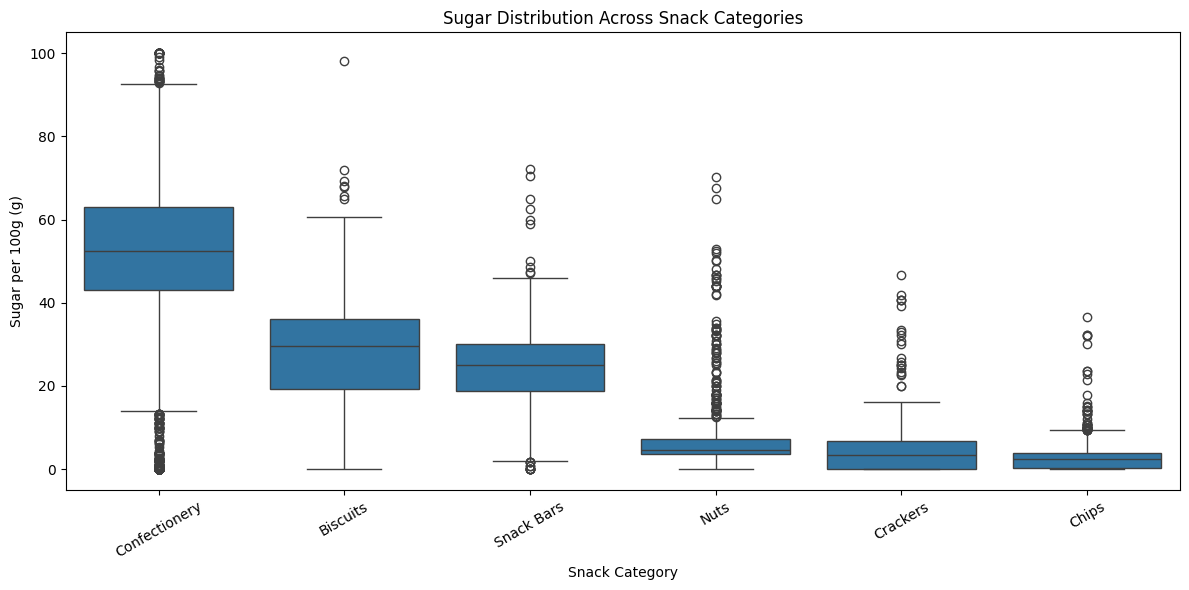

In [71]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=core_analysis_df,
    x="primary_category",
    y="sugars_100g",
    order=category_summary.index.tolist()
)

plt.title("Sugar Distribution Across Snack Categories")
plt.xlabel("Snack Category")
plt.ylabel("Sugar per 100g (g)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

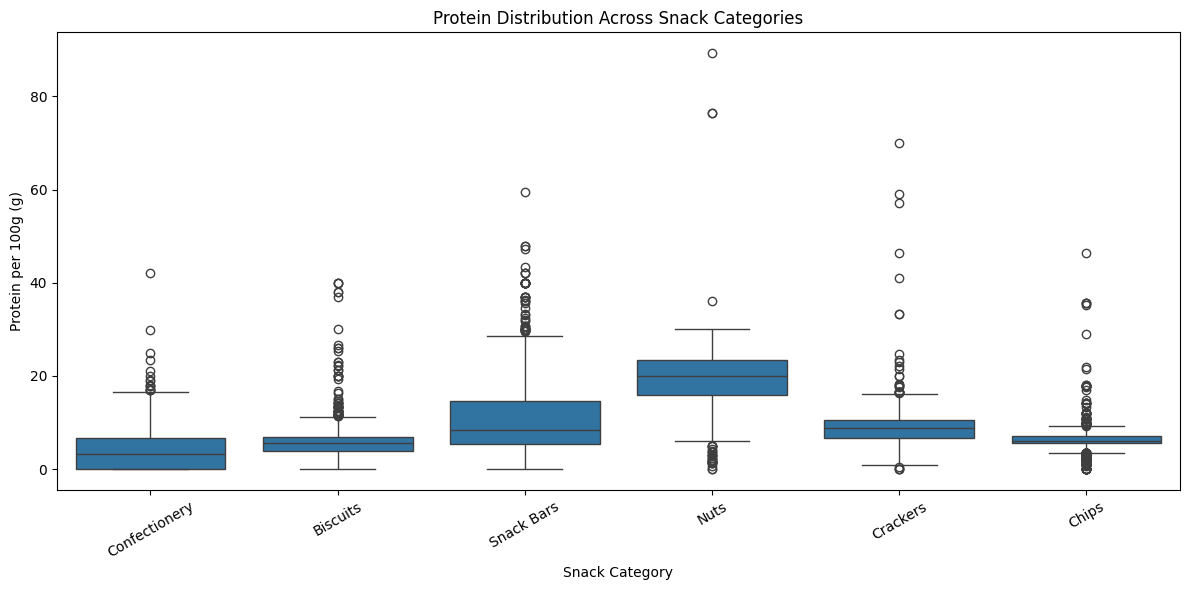

In [72]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=core_analysis_df,
    x="primary_category",
    y="proteins_100g",
    order=category_summary.index.tolist()
)

plt.title("Protein Distribution Across Snack Categories")
plt.xlabel("Snack Category")
plt.ylabel("Protein per 100g (g)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

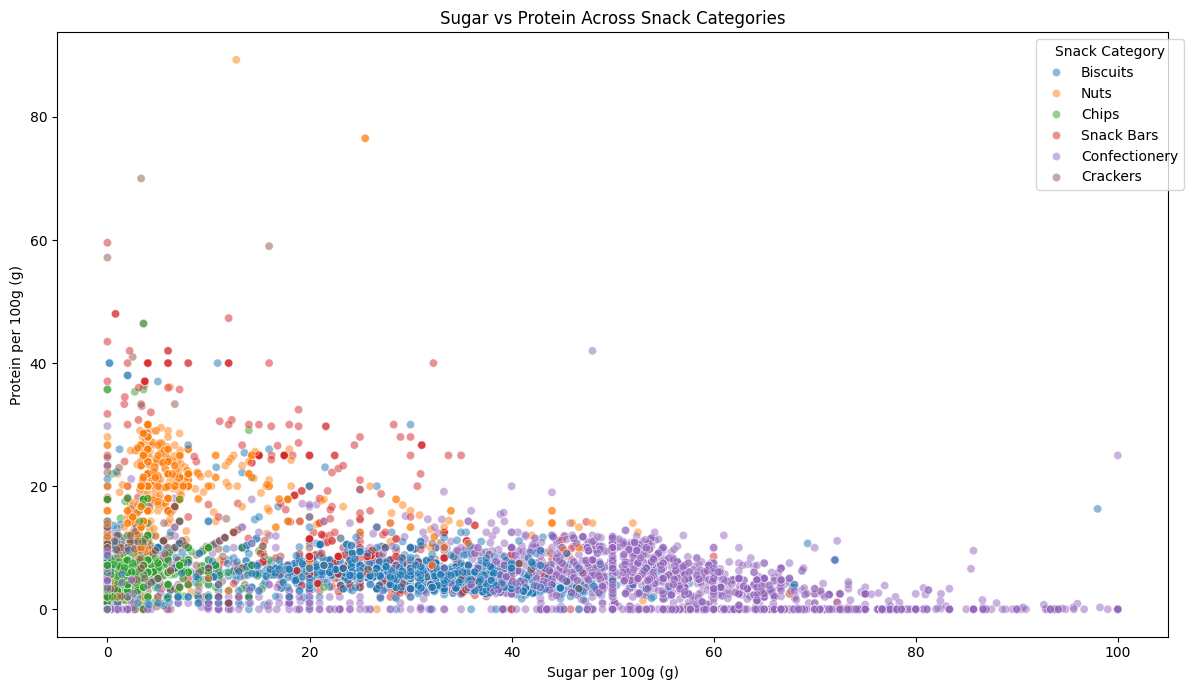

In [73]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=core_analysis_df,
    x="sugars_100g",
    y="proteins_100g",
    hue="primary_category",
    alpha=0.5,
    s=35
)

plt.title("Sugar vs Protein Across Snack Categories")
plt.xlabel("Sugar per 100g (g)")
plt.ylabel("Protein per 100g (g)")
plt.legend(title="Snack Category", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

In [74]:
# Define initial data-driven thresholds

low_sugar_threshold = core_analysis_df["sugars_100g"].quantile(0.25)
high_protein_threshold = core_analysis_df["proteins_100g"].quantile(0.75)

print("Low sugar threshold:", round(low_sugar_threshold, 2))
print("High protein threshold:", round(high_protein_threshold, 2))

# Identify products in the opportunity quadrant

opportunity_df = core_analysis_df[
    (core_analysis_df["sugars_100g"] <= low_sugar_threshold) &
    (core_analysis_df["proteins_100g"] >= high_protein_threshold)
].copy()

print("\nQualifying products:", len(opportunity_df))

Low sugar threshold: 3.57
High protein threshold: 8.33

Qualifying products: 580


In [75]:
opportunity_summary = (
    opportunity_df.groupby("primary_category")
    .size()
    .reindex(CATEGORY_PRIORITY, fill_value=0)
    .to_frame("Qualifying Products")
)

opportunity_summary["Category Total"] = (
    core_analysis_df["primary_category"]
    .value_counts()
    .reindex(CATEGORY_PRIORITY)
)

opportunity_summary["Opportunity Percentage"] = (
    opportunity_summary["Qualifying Products"] /
    opportunity_summary["Category Total"] * 100
).round(2)

display(opportunity_summary)

,Qualifying Products,Category Total,Opportunity Percentage
primary_category,,,
Snack Bars,19,485,3.92
Biscuits,106,1917,5.53
Crackers,173,498,34.74
Chips,48,1618,2.97
Confectionery,13,2649,0.49
Nuts,221,875,25.26


In [76]:
display(
    opportunity_df[
        [
            "product_name",
            "primary_category",
            "sugars_100g",
            "proteins_100g"
        ]
    ].sort_values(
        "proteins_100g",
        ascending=False
    ).head(20)
)

,product_name,primary_category,sugars_100g,proteins_100g
53832,protein PUFFS Garlic Parmesan,Crackers,3.333333,70.000000
230335,Opti-Meal Protein Bars strawberry,Snack Bars,0.000000,59.555556
148259,Pork crackling dippers,Crackers,0.000000,57.142857
12781,Perfectbar,Snack Bars,0.800000,48.000000
12780,Barretta perfectbar,Snack Bars,0.800000,48.000000
129597,TOMATO BASIL PIZZA CRISPS,Chips,3.571429,46.428571
129596,PEPPERONI PIZZA CRISPS,Crackers,3.571429,46.428571
92944,Crispy bars marshmallow,Snack Bars,0.000000,43.478261
12959,K Crisp,Snack Bars,2.200000,42.000000
12437,Crackers al rosmarino,Crackers,2.500000,41.000000


In [77]:
opportunity_summary["Profile Penetration (%)"] = (
    opportunity_summary["Qualifying Products"] /
    opportunity_summary["Category Total"] * 100
).round(2)

opportunity_summary["Nutritional Gap (%)"] = (
    100 - opportunity_summary["Profile Penetration (%)"]
).round(2)

opportunity_summary = opportunity_summary.sort_values(
    "Nutritional Gap (%)",
    ascending=False
)

display(opportunity_summary)

,Qualifying Products,Category Total,Opportunity Percentage,Profile Penetration (%),Nutritional Gap (%)
primary_category,,,,,
Confectionery,13,2649,0.49,0.49,99.51
Chips,48,1618,2.97,2.97,97.03
Snack Bars,19,485,3.92,3.92,96.08
Biscuits,106,1917,5.53,5.53,94.47
Nuts,221,875,25.26,25.26,74.74
Crackers,173,498,34.74,34.74,65.26


In [82]:
# Classify products into four nutritional quadrants

low_sugar = (
    core_analysis_df["sugars_100g"] <= low_sugar_threshold
)

high_protein = (
    core_analysis_df["proteins_100g"] >= high_protein_threshold
)

core_analysis_df["nutrient_quadrant"] = np.select(
    [
        low_sugar & high_protein,
        low_sugar & ~high_protein,
        ~low_sugar & high_protein
    ],
    [
        "High Protein / Low Sugar",
        "Low Protein / Low Sugar",
        "High Protein / High Sugar"
    ],
    default="Low Protein / High Sugar"
)

quadrant_summary = (
    core_analysis_df["nutrient_quadrant"]
    .value_counts()
    .to_frame("Product Count")
)

quadrant_summary["Percentage"] = (
    quadrant_summary["Product Count"] /
    len(core_analysis_df) * 100
).round(2)

display(quadrant_summary)

,Product Count,Percentage
nutrient_quadrant,,
Low Protein / High Sugar,4538,56.43
Low Protein / Low Sugar,1483,18.44
High Protein / High Sugar,1441,17.92
High Protein / Low Sugar,580,7.21


In [83]:
gem_df = opportunity_df.copy()

available_ingredients = (
    gem_df["ingredients_text"]
    .fillna("")
    .str.strip()
    .ne("")
)

print("Qualifying products:", len(gem_df))
print("Products with ingredient information:", available_ingredients.sum())
print("Products without ingredient information:",
      (~available_ingredients).sum())

Qualifying products: 580
Products with ingredient information: 459
Products without ingredient information: 121


In [84]:
PROTEIN_SOURCE_PATTERNS = {
    "Whey": r"\bwhey\b",
    "Peanuts": r"\bpeanuts?\b",
    "Soy protein / soybeans": (
        r"\bsoy protein\b|\bsoya protein\b|"
        r"\bsoybeans?\b|\bsoya beans?\b|"
        r"\bsoy flour\b|\bsoya flour\b"
    ),
    "Almonds": r"\balmonds?\b",
    "Pea protein": r"\bpea protein\b|\bpea protein isolate\b",
    "Milk protein": (
        r"\bmilk protein\b|\bmilk powder\b|"
        r"\bmilk solids\b|\bcasein\b"
    ),
    "Egg protein": r"\begg whites?\b|\begg powder\b",
    "Lentils": r"\blentils?\b"
}

ingredient_text = (
    gem_df["ingredients_text"]
    .fillna("")
    .str.lower()
)

source_counts = {}

for source, pattern in PROTEIN_SOURCE_PATTERNS.items():

    source_counts[source] = ingredient_text.str.contains(
        pattern,
        case=False,
        regex=True,
        na=False
    ).sum()

protein_sources = (
    pd.Series(source_counts, name="Product Count")
    .sort_values(ascending=False)
)

display(protein_sources.to_frame())

,Product Count
Soy protein / soybeans,120
Peanuts,78
Whey,69
Almonds,60
Milk protein,14
Lentils,9
Pea protein,5
Egg protein,2


In [85]:
top_three_sources = protein_sources.head(3)

print("Top 3 protein-source mentions:")
display(top_three_sources.to_frame())

Top 3 protein-source mentions:


,Product Count
Soy protein / soybeans,120
Peanuts,78
Whey,69
